# Econ 372 — Homework 3: Hospital Competition and Pricing

Wenshuo Wan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

def show():
    for ax in plt.gcf().axes:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.show()

COLS = {
    "id": "provider_number",
    "year": "year",
    "dis": "tot_discharges",
    "price": "price",
    "zip": "zip",
    "hrr": "hrr",
    "mkt": "mkt",
}
DATA_PATH = "../data/hospital-panel.csv"

raw = pd.read_csv(DATA_PATH)
df = raw.rename(columns={v: k for k, v in COLS.items()})
print("Raw rows:", len(df), "| years:", df["year"].min(), "-", df["year"].max())

# The assignment covers 1998-2017; the few 1997 and 2018 rows are partial years.
df = df[df["year"].between(1998, 2017)]

# One obvious data error: a Frederick, MD hospital reports 16 million discharges
# in 2000 (the next-largest hospital-year has ~156,000). Left in, it would swamp
# its market's shares, so I drop that single row.
print(df.nlargest(3, "dis")[["id", "city", "state", "year", "dis"]])
df = df[df["dis"] < 1_000_000]
df = df[df["dis"] > 0].copy()
print("Analysis rows:", len(df))
print("Missing market IDs:", df[["zip", "hrr", "mkt"]].isna().sum().to_dict())

Raw rows: 56942 | years: 1997 - 2018
           id        city state  year         dis
23703  210005   FREDERICK    MD  2000  16013780.0
37305  340141  WILMINGTON    NC  2013    155781.0
10044  100007     ORLANDO    FL  2016    136833.0
Analysis rows: 55820
Missing market IDs: {'zip': 21, 'hrr': 1580, 'mkt': 6635}


# Q1 — Market definition and concentration

## (a) HHI three ways

In [2]:
DEFS = {"zip": "Zip code", "hrr": "HRR", "mkt": "Community detection"}

def market_table(data, mdef):
    """One row per market-year: HHI, max share, # hospitals, total discharges."""
    d = data[data[mdef].notna()].copy()
    d["mkt_dis"] = d.groupby([mdef, "year"])["dis"].transform("sum")
    d["share"] = d["dis"] / d["mkt_dis"]
    out = (d.groupby([mdef, "year"])
             .agg(hhi=("share", lambda s: 10000 * (s ** 2).sum()),
                  max_share=("share", "max"),
                  share_sum=("share", "sum"),
                  n_hosp=("id", "nunique"),
                  mkt_dis=("dis", "sum"))
             .reset_index()
             .rename(columns={mdef: "market"}))
    out["definition"] = DEFS[mdef]
    return out, d

tables, hosp = {}, {}
for m in DEFS:
    tables[m], hosp[m] = market_table(df, m)
mk = pd.concat(tables.values(), ignore_index=True)
mk.groupby("definition")[["market", "n_hosp", "hhi"]].agg(
    {"market": "nunique", "n_hosp": "mean", "hhi": "mean"}).round(1)

,market,n_hosp,hhi
definition,,,
Community detection,603,4.5,5446.5
HRR,306,8.9,3189.9
Zip code,4080,1.1,9749.2


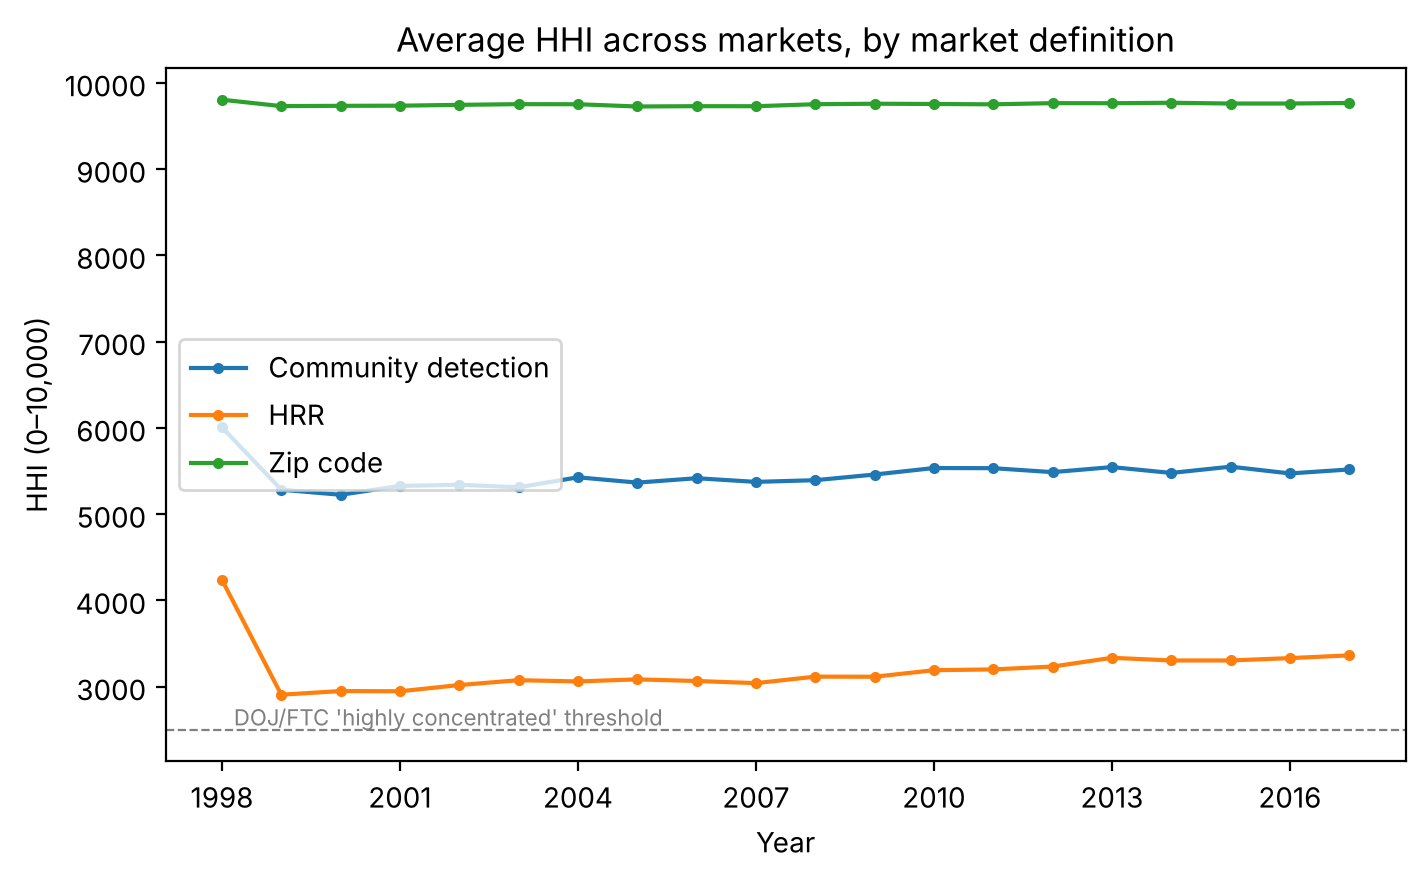

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, g in mk.groupby("definition"):
    s = g.groupby("year")["hhi"].mean()
    ax.plot(s.index, s.values, marker="o", ms=3, label=name)
ax.set(title="Average HHI across markets, by market definition",
       xlabel="Year", ylabel="HHI (0–10,000)")
ax.axhline(2500, ls="--", c="grey", lw=0.8)
ax.text(1998.2, 2550, "DOJ/FTC 'highly concentrated' threshold", fontsize=8, color="grey")
ax.legend(); show()

**Answer (a).** The three definitions give very different pictures. Averaged across markets, the zip-code HHI is about 9,750 throughout 1998–2017, essentially every zip code looks like a monopoly. Community-detection markets average about 5,450 and HRRs about 3,190. All three are above the DOJ/FTC "highly concentrated" threshold of 2,500. The first year is an outlier: 1998 has only about 2,000 hospitals in the panel versus over 3,100 in 1999, so markets look mechanically more concentrated that year, and the drop from 1998 to 1999 is a sample artifact, not a wave of entry. From 1999 on, concentration rises gradually: community-detection HHI goes from 5,282 in 1999 to 5,517 in 2017, and HRR HHI from 2,906 to 3,362. That fits steady hospital consolidation, including the merger wave of the 2010s. The zip-code measure is flat near 10,000 and shows almost nothing. The ranking follows the size of the geography. A zip code is a papaya-sized slice of the country with about 1.1 hospitals on average, an HRR contains about 9, and a community-detection market about 4.5. Cutting the same papaya into thinner slices does not change the fruit, only how concentrated each slice looks.

## (b) Why the definition matters

**Answer (b).** HHI is computed from shares *within* a market, so the market definition decides who counts as a competitor. Zip codes are too narrow: patients routinely cross zip-code lines, so a hospital that is "alone" in its zip code still competes with hospitals a few miles away, and the zip-code HHI overstates concentration. HRRs are too broad: they are built around referrals for major cardiovascular surgery and neurosurgery, so they lump together hospitals that do not compete for the same routine patients and understate concentration. The economically "correct" market is the antitrust market: the smallest group of hospitals over which a hypothetical monopolist could profitably raise price (the hypothetical monopolist or SSNIP test). That depends on how far patients are willing to travel, which differs by service (childbirth vs. transplants), by patient (rural vs. urban), and by insurer network. So there is no single right answer. The community-detection markets are a reasonable compromise because they group hospitals that actually share patient flows, but they still impose one market on every service.

## (c) The problem with a simple average

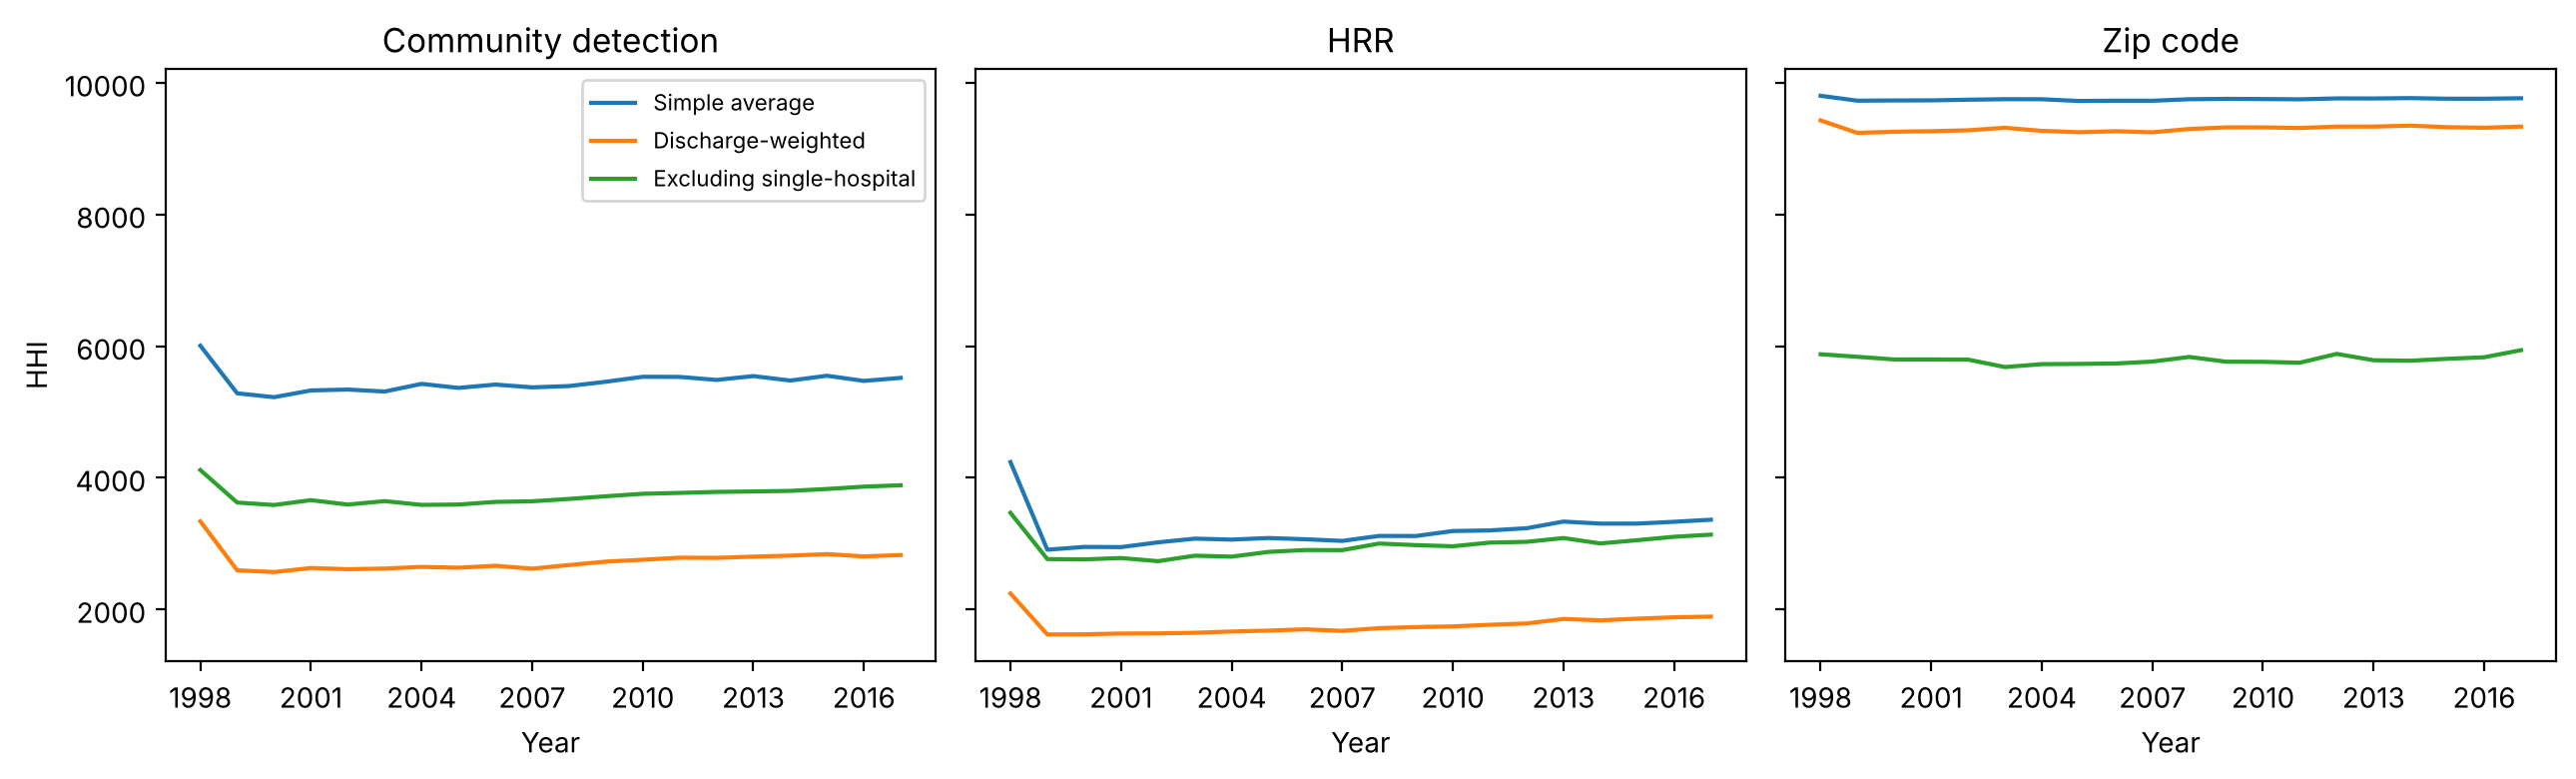

,Simple average,Discharge-weighted,Excluding single-hospital,Share single-hospital
definition,,,,
Community detection,5451.29,2735.91,3727.51,0.27
HRR,3193.02,1757.54,2956.89,0.03
Zip code,9750.46,9303.78,5793.27,0.94


In [4]:
rows = []
for name, g in mk.groupby("definition"):
    for yr, gy in g.groupby("year"):
        multi = gy[gy["n_hosp"] > 1]
        rows.append({"definition": name, "year": yr,
                     "Simple average": gy["hhi"].mean(),
                     "Discharge-weighted": np.average(gy["hhi"], weights=gy["mkt_dis"]),
                     "Excluding single-hospital": multi["hhi"].mean(),
                     "Share single-hospital": (gy["n_hosp"] == 1).mean()})
avg = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (name, g) in zip(axes, avg.groupby("definition")):
    for col in ["Simple average", "Discharge-weighted", "Excluding single-hospital"]:
        ax.plot(g["year"], g[col], label=col)
    ax.set(title=name, xlabel="Year")
axes[0].set_ylabel("HHI"); axes[0].legend(fontsize=8); plt.tight_layout(); show()

avg.groupby("definition")[["Simple average", "Discharge-weighted",
                            "Excluding single-hospital", "Share single-hospital"]].mean().round(2)

**Answer (c).** The unweighted average treats a one-hospital rural market the same as a market with dozens of hospitals. Single-hospital markets make up 94% of zip-code market-years, 27% of community-detection market-years, and 3% of HRR market-years. Weighting each market by its total discharges cuts the average community-detection HHI from about 5,450 to 2,740 and the HRR average from 3,190 to 1,760. Excluding single-hospital markets gives 3,730 and 2,960. Zip codes barely move when weighted (9,750 to 9,300) because even large zip codes usually have only one hospital, which is another sign the definition is too narrow. The simple average answers "how concentrated is the typical *market*?" The weighted average answers "how concentrated is the market the typical *patient* faces?", which is closer to the welfare question. What the plain average was leaving out is that most patients are treated in large, multi-hospital markets. The many small monopoly markets dominate the count but serve a small share of patients.

## (d) A sanity check on the join

In [5]:
for m in DEFS:
    bad = tables[m][~np.isclose(tables[m]["share_sum"], 1)]
    print(f"{DEFS[m]:22s} market-years where shares != 1: {len(bad)}")

# Illustration of a careless join: compute the denominator by one grouping
# but attach it to hospitals using a mismatched market key (shuffled within year).
d = df[df["mkt"].notna()].copy()
tot = d.groupby(["mkt", "year"])["dis"].sum().rename("mkt_dis").reset_index()
rng = np.random.default_rng(0)
d["mkt_wrong"] = d.groupby("year")["mkt"].transform(lambda s: rng.permutation(s.values))
bad_join = d.merge(tot, left_on=["mkt_wrong", "year"], right_on=["mkt", "year"],
                   suffixes=("", "_tot"))
bad_join["share"] = bad_join["dis"] / bad_join["mkt_dis"]
chk = bad_join.groupby(["mkt", "year"])["share"].agg(["sum", lambda s: 10000 * (s ** 2).sum()])
chk.columns = ["share_sum", "hhi"]
print(chk["share_sum"].describe().round(2))
print("Avg HHI, correct join:", round(tables["mkt"]["hhi"].mean()),
      "| mismatched join:", round(chk["hhi"].mean()))

Zip code               market-years where shares != 1: 0
HRR                    market-years where shares != 1: 0
Community detection    market-years where shares != 1: 0


count    11027.00
mean         1.72
std          3.53
min          0.00
25%          0.15
50%          0.55
75%          1.74
max         63.79
Name: share_sum, dtype: float64
Avg HHI, correct join: 5447 | mismatched join: 74449


**Answer (d).** With the correct grouping, shares sum to exactly 1 in every market-year for all three definitions (zero failures), as they should by construction. To show what a careless join does, I attached each hospital to a randomly mismatched community-detection market's total discharges. Shares then summed to anywhere from almost 0 to 64 within a market-year (mean 1.72), individual "shares" exceeded 1, and the average HHI jumped from 5,447 to 74,449, which is impossible since HHI cannot exceed 10,000. A mismatch silently breaks the link between the numerator (a hospital's discharges) and the denominator (its market's total), so HHI becomes meaningless. Related mistakes behave the same way: duplicate rows from a many-to-many merge push the share sum above 1, and hospitals dropped by an inner join make markets look smaller and more concentrated than they are. That is why the check is worth running every time.

## (e) Maximum share instead of HHI

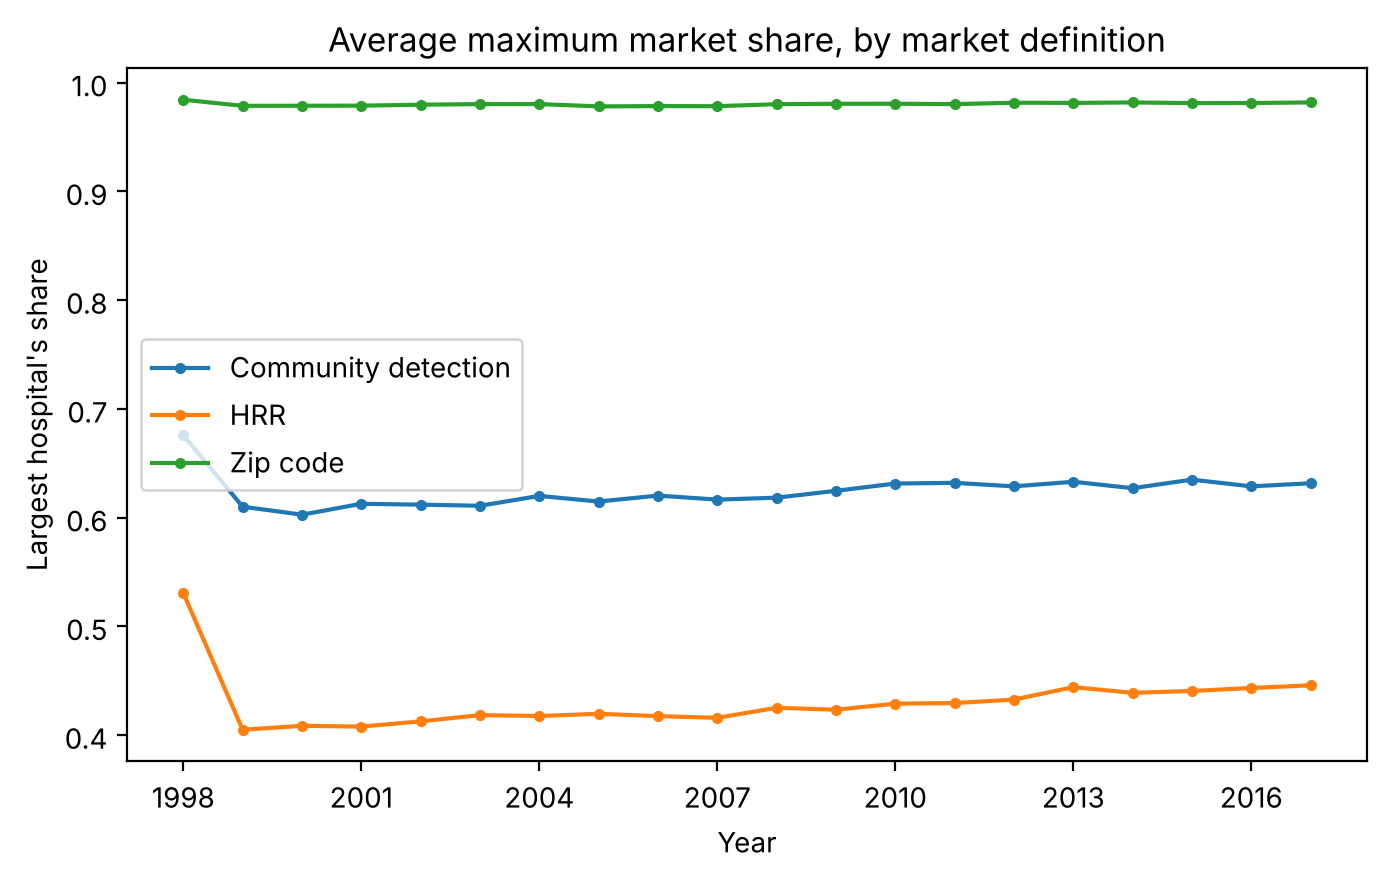

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, g in mk.groupby("definition"):
    s = g.groupby("year")["max_share"].mean()
    ax.plot(s.index, s.values, marker="o", ms=3, label=name)
ax.set(title="Average maximum market share, by market definition",
       xlabel="Year", ylabel="Largest hospital's share"); ax.legend(); show()

**Answer (e).** The largest hospital's share tells the same broad story. It averages 0.98 in zip codes, 0.62 in community-detection markets, and 0.43 in HRRs. It follows the same time path as HHI: after the 1998 sample artifact, it rises from 0.61 in 1999 to 0.63 in 2017 in community-detection markets and from 0.41 to 0.45 in HRRs. So the ranking of definitions and the trend are robust to the measure. The difference is what each measure sees. Max share looks only at the leader, while HHI uses every firm's share. Two markets where the leader has 50% look identical by max share, but very different by HHI if the other 50% is held by one rival rather than split across ten small hospitals. That fringe matters in hospital markets because an insurer can credibly leave a dominant hospital out of its network only if close substitutes remain. Because the two measures move together here, most of the variation in concentration comes from the size of the leading hospital.

# Q2 — Prices and market structure (community-detection markets)

In [7]:
h = hosp["mkt"].merge(tables["mkt"][["market", "year", "n_hosp"]],
                      left_on=["mkt", "year"], right_on=["market", "year"])
h["structure"] = np.select([h["n_hosp"] <= 2, h["n_hosp"] >= 4],
                           ["Monopoly/duopoly", "Competitive (4+)"], "Three hospitals")

## (a) The price variable

count    49185.0
mean      8095.0
std       4991.0
min          6.0
1%        1307.0
5%        2558.0
25%       4848.0
50%       7100.0
75%      10116.0
95%      16731.0
99%      25392.0
max      97689.0
Name: price, dtype: float64
Missing: 0 | <= 0: 0


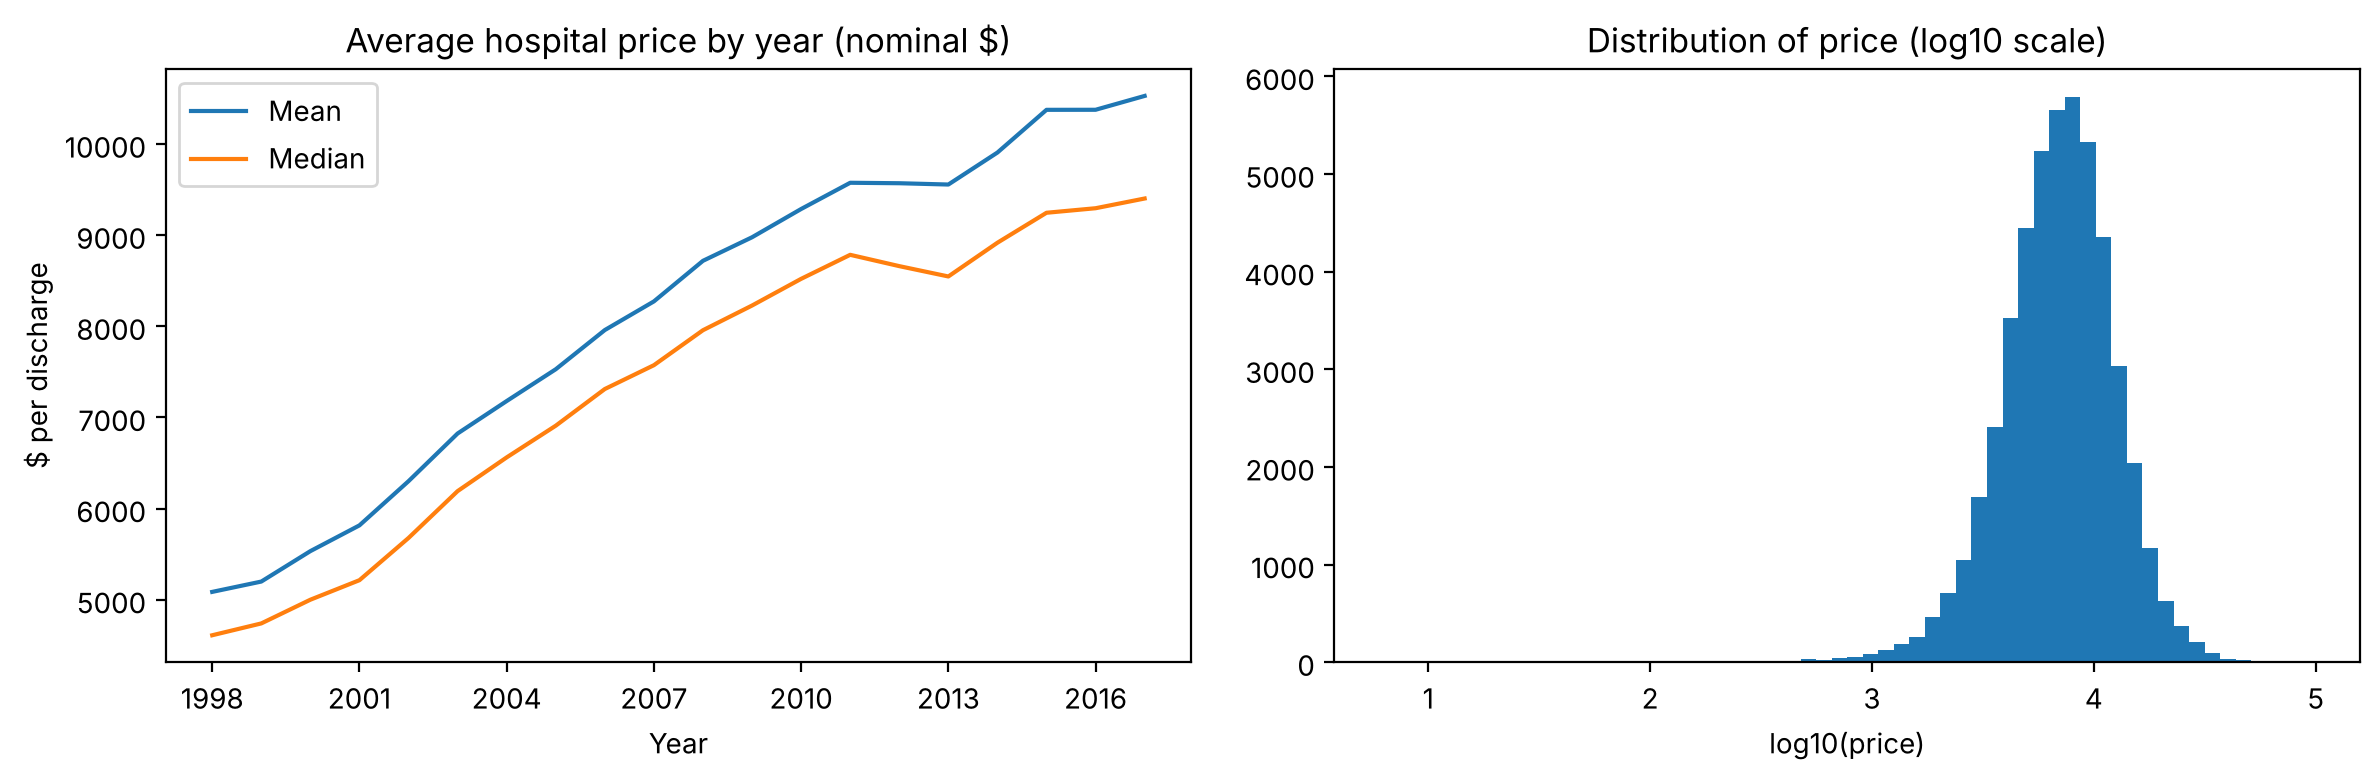

In [8]:
p = h["price"]
print(p.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(0))
print("Missing:", p.isna().sum(), "| <= 0:", (p <= 0).sum())

yr = h.groupby("year")["price"].agg(mean="mean", median="median")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(yr.index, yr["mean"], label="Mean"); axes[0].plot(yr.index, yr["median"], label="Median")
axes[0].set(title="Average hospital price by year (nominal $)", xlabel="Year", ylabel="$ per discharge")
axes[0].legend()
pos = p[(p > 0)]
axes[1].hist(np.log10(pos), bins=60)
axes[1].set(title="Distribution of price (log10 scale)", xlabel="log10(price)")
plt.tight_layout(); show()

**Answer (a).** The average price roughly doubles, from about $5,085 in 1998 to $10,529 in 2017 (median: $4,609 to $9,403). The variable is very spread out: in the analysis sample it runs from $6 to about $97,700, with a 1st percentile of $1,307, a 99th percentile of $25,392, and a coefficient of variation of 0.62. The mean sits above the median every year because of a long right tail. Values near zero and near $100,000 cannot be real per-stay prices, so they reflect accounting noise. What it captures: rough average revenue per non-Medicare stay, built from charges adjusted toward what is actually paid, after removing Medicare. What it does not capture: (1) the price of any specific service, since it averages over very different case mixes, so a hospital that treats sicker patients looks "expensive"; (2) separate private, Medicaid, and self-pay prices, which are pooled; (3) negotiated prices observed directly, since it is backed out of charges and accounting ratios; (4) real changes, since it is nominal. CPI rose about 50% from 1998 to 2017, so roughly half of the doubling is general inflation. The rest mixes rising case-mix intensity, payer-mix shifts, and accounting changes with any real price growth. Like a rhubarb pie that is mostly sugar, the trend is a blend, so I read it as suggestive rather than as a clean price index. A fair reading would deflate it, use the median or trim extremes, and treat the rhubarb (the real price change) as only one ingredient.

## (b) Concentrated vs competitive markets

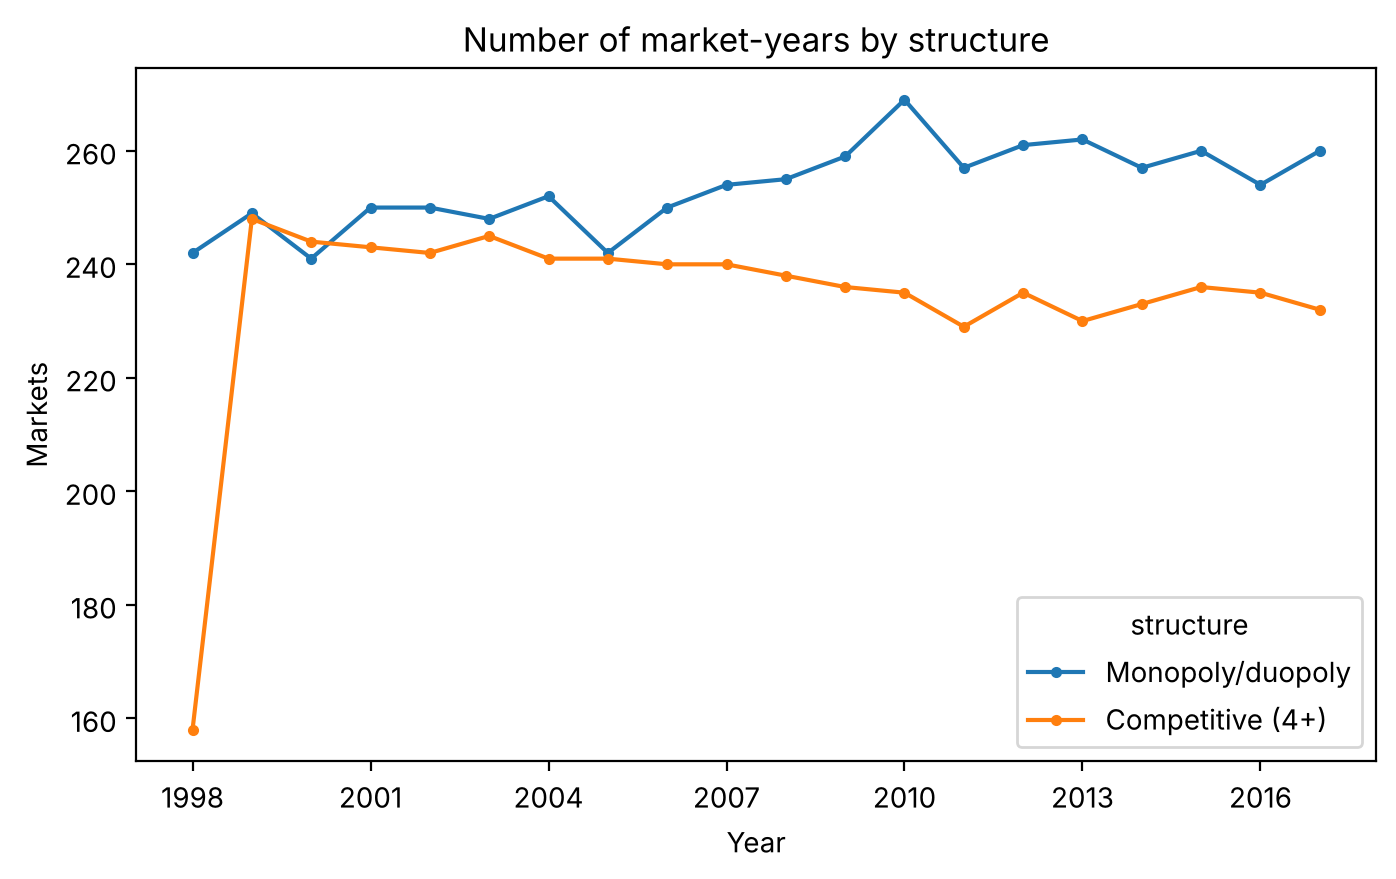

structure,Monopoly/duopoly,Three hospitals,Competitive (4+)
year,,,
1998,242,64,158
1999,249,64,248
2000,241,71,244
2001,250,70,243
2002,250,69,242
2003,248,68,245
2004,252,72,241
2005,242,63,241
2006,250,60,240


In [9]:
cnt = (tables["mkt"].assign(structure=np.select(
            [tables["mkt"]["n_hosp"] <= 2, tables["mkt"]["n_hosp"] >= 4],
            ["Monopoly/duopoly", "Competitive (4+)"], "Three hospitals"))
       .groupby(["year", "structure"]).size().unstack(fill_value=0))
cnt = cnt.reindex(columns=["Monopoly/duopoly", "Three hospitals", "Competitive (4+)"], fill_value=0)
cnt[["Monopoly/duopoly", "Competitive (4+)"]].plot(marker="o", ms=3, figsize=(8, 4.5),
    title="Number of market-years by structure", ylabel="Markets", xlabel="Year")
show(); cnt

**Answer (b).** Each year there are about 250–260 monopoly/duopoly market-years and about 230–245 competitive (4+ hospital) market-years in the community-detection definition. Monopolies and duopolies slowly become more common, from about 241–252 a year in 1998–2004 to about 259 on average in 2008–2017, while competitive markets decline from about 245 to about 232. That is consistent with consolidation and hospital closures, mainly in smaller markets. The low 1998 count of competitive markets (158) reflects the smaller number of hospitals reporting that year, not a real change. The counts can also move when hospitals enter or leave the HCRIS sample, not only through mergers.

## (c) Price by market structure

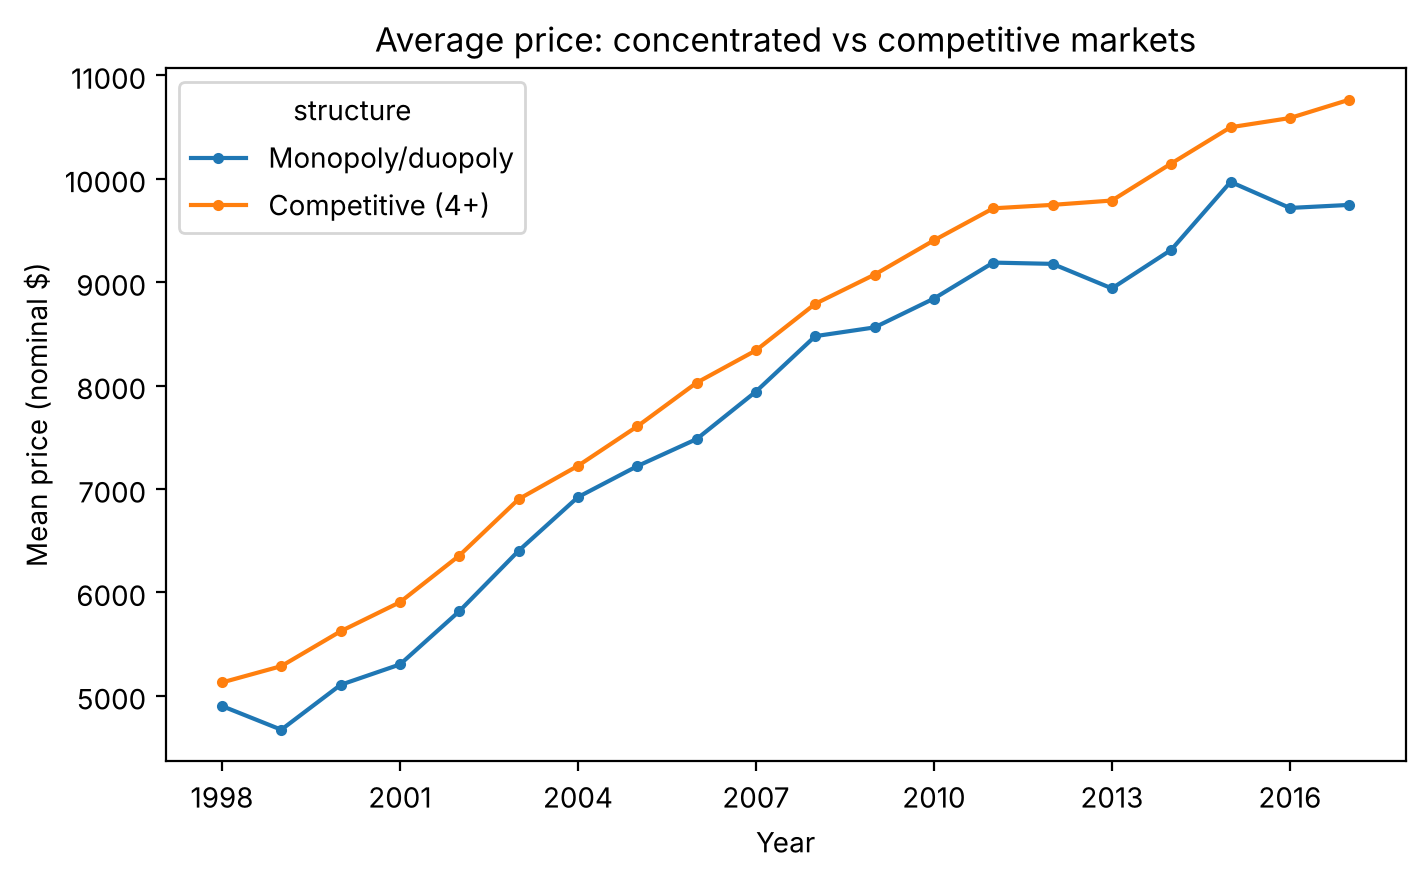

structure,Monopoly/duopoly,Competitive (4+),gap
year,,,
1998,4901.0,5129.0,-228.0
1999,4672.0,5287.0,-615.0
2000,5106.0,5624.0,-518.0
2001,5303.0,5905.0,-602.0
2002,5817.0,6355.0,-538.0
2003,6402.0,6901.0,-499.0
2004,6921.0,7223.0,-303.0
2005,7221.0,7605.0,-384.0
2006,7482.0,8027.0,-545.0


In [10]:
def price_by_structure(data, title):
    sub = data[data["structure"] != "Three hospitals"]
    t = (sub.groupby(["year", "structure"])["price"].mean().unstack()
           .reindex(columns=["Monopoly/duopoly", "Competitive (4+)"]))
    t.plot(marker="o", ms=3, figsize=(8, 4.5), title=title,
           ylabel="Mean price (nominal $)", xlabel="Year")
    show()
    return t.assign(gap=t["Monopoly/duopoly"] - t["Competitive (4+)"]).round(0)

price_by_structure(h, "Average price: concentrated vs competitive markets")

**Answer (c).** In the raw data, concentrated markets have *lower* average prices. Every year from 1998 to 2017 the monopoly/duopoly average is below the competitive average, by about $230 in 1998 and about $1,020 in 2017 (overall $7,731 vs. $8,199). Taken at face value, this suggests concentration is associated with lower prices, the opposite of what market-power theory predicts. Part (d) shows why this comparison is misleading.

## (d) The market-size confound

Market-years kept: 5114


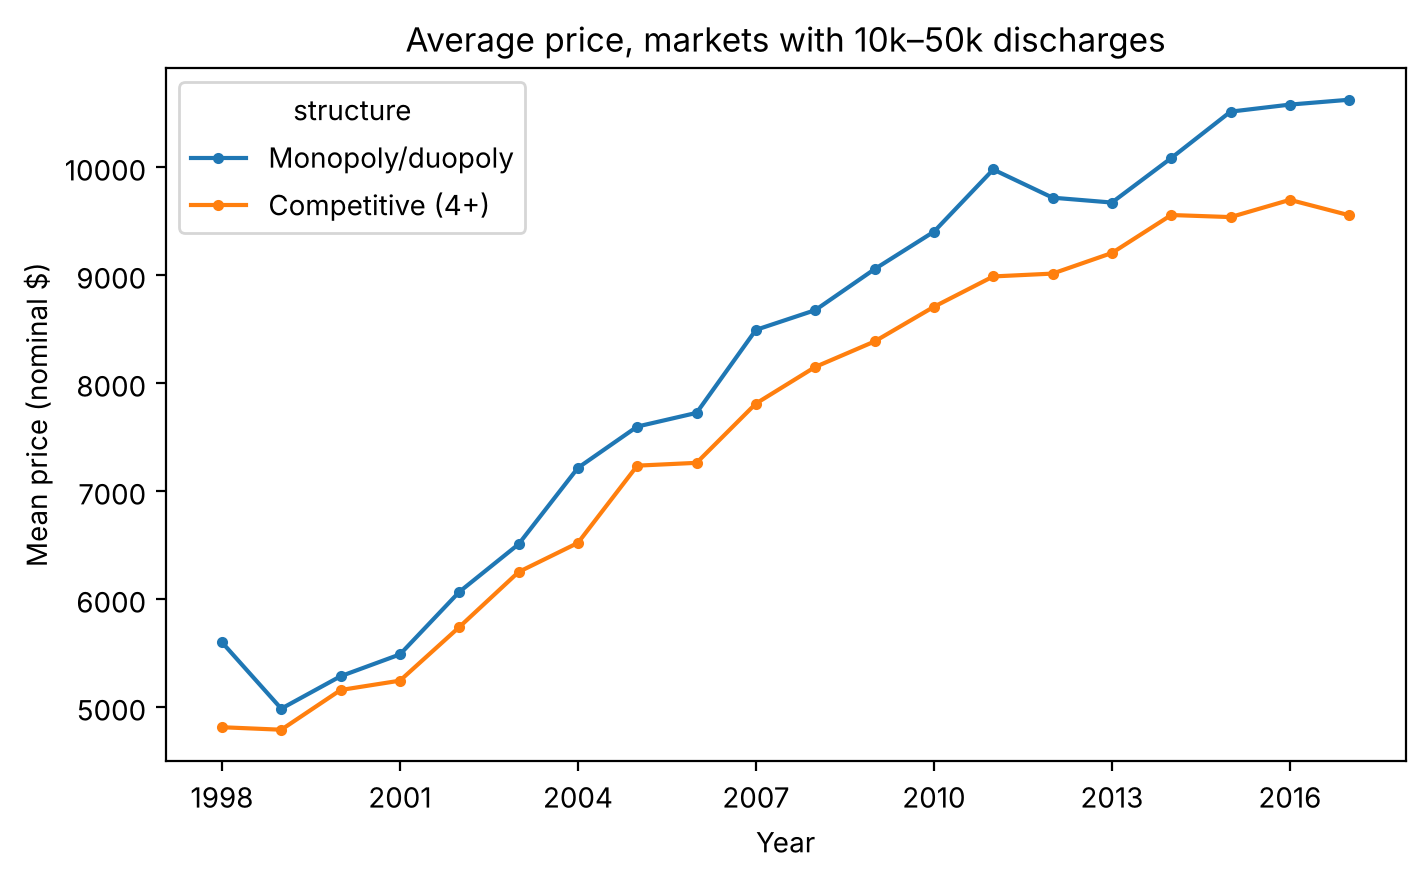

structure,Monopoly/duopoly,Competitive (4+),gap
year,,,
1998,5598.0,4812.0,787.0
1999,4983.0,4788.0,195.0
2000,5284.0,5156.0,128.0
2001,5486.0,5243.0,243.0
2002,6065.0,5739.0,326.0
2003,6507.0,6249.0,258.0
2004,7214.0,6519.0,695.0
2005,7596.0,7234.0,362.0
2006,7723.0,7260.0,463.0


In [11]:
mid = h[(h["mkt_dis"] >= 10000) & (h["mkt_dis"] <= 50000)]
print("Market-years kept:", mid.groupby(["mkt", "year"]).ngroups)
price_by_structure(mid, "Average price, markets with 10k–50k discharges")

**Answer (d).** The sign flips. Among markets with 10,000–50,000 total discharges (5,114 market-years), monopoly/duopoly markets have *higher* prices than competitive ones in every year, by about $790 in 1998 and $1,070 in 2017 (overall $8,354 vs. $7,401). Market size drives both concentration and price. In the full sample, the median monopoly/duopoly market has about 8,400 discharges a year while the median competitive market has about 59,600. Small, rural markets can support only one or two hospitals, and they also have lower wages and land costs, simpler cases, more Medicaid and uninsured patients, and smaller, less specialized hospitals, all of which lower this constructed price. Large urban markets have many hospitals *and* high costs and complex care. Comparing a rural monopoly to a big-city competitive market mostly compares rural to urban, which hides the market-power effect. Holding size roughly fixed removes much of that confounding, and the remaining gap goes in the direction theory predicts.

## (e) Is it causal?

**Answer (e).** No. Even the size-restricted comparison is a correlation, not causal evidence. Market structure is not randomly assigned: within the 10,000–50,000 band, concentrated and competitive markets can still differ in costs, case mix, payer mix, quality, and demand, and causality can run the other way (profitable markets attract entry; struggling hospitals close or merge). The price measure also mixes case mix with price, so a "higher price" may partly be sicker patients. To make a causal claim I would need variation in concentration that affects price only through competition, for example: (1) a difference-in-differences design around hospital mergers, comparing price changes at merging hospitals that were close substitutes with similar non-merging hospitals, as in Cooper, Craig, Gaynor and Van Reenen (2019); (2) mergers between hospitals in different markets, or closures, as a source of variation unrelated to local demand; or (3) a structural model of insurer–hospital bargaining. All of these work best with transaction prices for specific procedures from commercial claims (e.g. HCCI), rather than this constructed HCRIS measure.